In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import linregress

# Paths (edit if your notebook lives elsewhere)
volume_csv = Path("../../Results/Volume/Volume.csv")
pca_csv = Path("../../Results/PCA/PCA_Spore_Scores_Aggregated_with_Count.csv")

# Output names
out_csv = pca_csv.with_name(pca_csv.stem + "_with_terminal_velocity.csv")
out_svg = pca_csv.with_name("PC1_vs_relative_terminal_velocity_broadside.svg")

In [2]:
vol_df = pd.read_csv(volume_csv)
pca_df = pd.read_csv(pca_csv)

print("Volume rows:", len(vol_df), " | PCA rows:", len(pca_df))
print("Volume cols:", list(vol_df.columns))
print("PCA cols:", list(pca_df.columns))


Volume rows: 153  | PCA rows: 212
Volume cols: ['species', 'Bas (1969), page', 'Alternative Source', 'Online Ref.', 'min_length', 'max_length', 'avg_length', 'min_width', 'max_width', 'avg_width', 'min_volume_estimated', 'max_volume_estimated', 'avg_volume_estimated']
PCA cols: ['species', 'num_samples', 'PC1_mean', 'PC1_min', 'PC1_max', 'PC1_sd', 'PC2_mean', 'PC2_min', 'PC2_max', 'PC2_sd', 'PC3_mean', 'PC3_min', 'PC3_max', 'PC3_sd', 'PC4_mean', 'PC4_min', 'PC4_max', 'PC4_sd', 'PC5_mean', 'PC5_min', 'PC5_max', 'PC5_sd']


In [3]:
def add_terminal_velocity_columns(
    vol_df: pd.DataFrame,
    length_col: str = "avg_length",           # diameter (µm)
    width_col: str = "avg_width",             # diameter (µm)
    vol_col: str = "avg_volume_estimated",    # µm^3, consistent with diameter-based prolate volume
) -> pd.DataFrame:
    """
    Adds Stokes-regime settling-speed proxies (constants omitted) for a prolate spheroid in two limiting orientations:

      tv_*_long_axis_down   : long axis aligned with gravity (streamlined)
      tv_*_short_axis_down  : long axis parallel to ground (broadside / highest drag)

    Returns both raw proxies and mean-normalized (dimensionless) versions.
    """
    df = vol_df.copy()

    # Extract arrays
    L = df[length_col].astype(float).to_numpy()  # diameter
    W = df[width_col].astype(float).to_numpy()   # diameter
    V = df[vol_col].astype(float).to_numpy()

    # Keep diameters for continuity with your current pipeline (mean-normalized values unaffected by semiaxis conversion)
    a = L.copy()
    c = W.copy()

    # Ensure prolate assumption (a >= c); swap if needed
    swap = c > a
    if np.any(swap):
        a2 = a.copy()
        c2 = c.copy()
        a2[swap], c2[swap] = c[swap], a[swap]
        a, c = a2, c2

    sphere = np.isclose(a, c, rtol=1e-12, atol=0.0)
    nons = ~sphere

    tv_long = np.full_like(V, np.nan, dtype=float)
    tv_short = np.full_like(V, np.nan, dtype=float)

    # Sphere proxy
    tv_long[sphere] = V[sphere] / a[sphere]
    tv_short[sphere] = V[sphere] / a[sphere]

    # Prolate eccentricity: e = sqrt(1 - (c/a)^2)
    ratio = np.clip(c[nons] / a[nons], 0.0, 1.0)
    e = np.sqrt(np.clip(1.0 - ratio**2, 0.0, 1.0))
    e_clip = np.clip(e, 0.0, 1.0 - 1e-15)
    log_term = np.log((1.0 + e_clip) / (1.0 - e_clip))

    Xa = (8.0 / 3.0) * e_clip**3 / (-2.0 * e_clip + (1.0 + e_clip**2) * log_term)
    Ya = (16.0 / 3.0) * e_clip**3 / ( 2.0 * e_clip + (3.0 * e_clip**2 - 1.0) * log_term)

    tv_long[nons] = V[nons] / (a[nons] * Xa)
    tv_short[nons] = V[nons] / (a[nons] * Ya)

    # Mean-normalized (dimensionless)
    tv_rel_long = tv_long / np.nanmean(tv_long)
    tv_rel_short = tv_short / np.nanmean(tv_short)

    df["tv_proxy_long_axis_down"] = tv_long
    df["tv_proxy_short_axis_down"] = tv_short
    df["tv_rel_long_axis_down"] = tv_rel_long
    df["tv_rel_short_axis_down"] = tv_rel_short

    # helpful extras
    df["aspect_ratio_LW"] = L / W
    df["tv_ratio_long_over_short"] = tv_long / tv_short

    return df


In [4]:
vol_tv = add_terminal_velocity_columns(vol_df)

# Quick sanity checks
print("Computed TV columns. Example rows:")
display(vol_tv[["species", "avg_length", "avg_width", "avg_volume_estimated",
                "tv_rel_long_axis_down", "tv_rel_short_axis_down",
                "aspect_ratio_LW", "tv_ratio_long_over_short"]].head())

print("Non-NA TV rows:", vol_tv["tv_rel_short_axis_down"].notna().sum(), "/", len(vol_tv))


Computed TV columns. Example rows:


,species,avg_length,avg_width,avg_volume_estimated,tv_rel_long_axis_down,tv_rel_short_axis_down,aspect_ratio_LW,tv_ratio_long_over_short
0,Amanita_lippiae,15.50,9.0,657.358875,1.917245,1.858763,1.722222,1.113430
1,Amanita_loosii,12.00,10.0,628.300000,1.818598,1.892799,1.200000,1.037150
2,Amanita_strobilaceovolvata,13.50,9.0,572.538375,1.738876,1.731585,1.500000,1.084013
3,Amanita_fulva,10.95,10.7,656.398361,1.838706,1.975673,1.023364,1.004631
4,Amanita_murinoflammeum,11.80,9.5,557.590071,1.684997,1.741721,1.242105,1.044311


Non-NA TV rows: 153 / 153


In [6]:
# Keep only columns you want to carry over
tv_cols = [
    "species",
    "tv_proxy_short_axis_down",
    "tv_rel_short_axis_down",
    "tv_proxy_long_axis_down",
    "tv_rel_long_axis_down",
    "aspect_ratio_LW",
    "tv_ratio_long_over_short"
]

merged = pca_df.merge(vol_tv[tv_cols], on="species", how="left")

print("Merged rows:", len(merged))
print("Rows with TV (broadside):", merged["tv_rel_short_axis_down"].notna().sum())

# Remove outlier species
outlier_species = ["Amanita_aurea", "Amanita_virosa"]
merged = merged[~merged["species"].isin(outlier_species)]

print(f"Removed {len(outlier_species)} species")
print(f"Remaining rows: {len(merged)}")


Merged rows: 212
Rows with TV (broadside): 150
Removed 2 species
Remaining rows: 210


In [7]:
merged.to_csv(out_csv, index=False)
print("Wrote merged CSV:", out_csv)


Wrote merged CSV: ..\..\Results\PCA\PCA_Spore_Scores_Aggregated_with_Count_with_terminal_velocity.csv


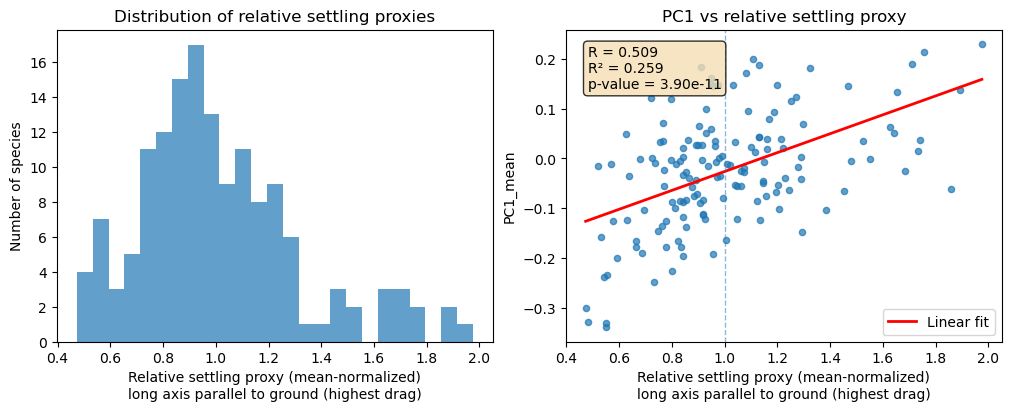

Wrote SVG: ..\..\Results\PCA\PC1_vs_relative_terminal_velocity_broadside.svg
Plotted points: 148


In [11]:
tv_col = "tv_rel_short_axis_down"  # highest drag: long axis parallel to ground
pc1_col = "PC1_mean"

plot_df = merged[[tv_col, pc1_col]].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

# Panel A: histogram
ax1.hist(plot_df[tv_col], bins=25, alpha=0.7)
ax1.set_xlabel("Relative settling proxy (mean-normalized)\nlong axis parallel to ground (highest drag)")
ax1.set_ylabel("Number of species")
ax1.set_title("Distribution of relative settling proxies")

# Panel B: scatter with regression line
ax2.scatter(plot_df[tv_col], plot_df[pc1_col], s=20, alpha=0.7)

# Calculate linear regression
slope, intercept, r_value, p_value, std_err = linregress(plot_df[tv_col], plot_df[pc1_col])
r_squared = r_value ** 2

# Plot regression line
x_line = np.array([plot_df[tv_col].min(), plot_df[tv_col].max()])
y_line = slope * x_line + intercept
ax2.plot(x_line, y_line, color='red', linewidth=2, label='Linear fit')

# Add statistics text
stats_text = f'R = {r_value:.3f}\nR² = {r_squared:.3f}\np-value = {p_value:.2e}'
ax2.text(0.05, 0.95, stats_text, transform=ax2.transAxes, 
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
         fontsize=10)

ax2.axvline(1.0, linestyle="--", linewidth=1, alpha=0.5)
ax2.set_xlabel("Relative settling proxy (mean-normalized)\nlong axis parallel to ground (highest drag)")
ax2.set_ylabel("PC1_mean")
ax2.set_title("PC1 vs relative settling proxy")
ax2.legend()

fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig("PC1_vs_relative_terminal_velocity_broadside.png", format="png", bbox_inches="tight")

plt.show()

print("Wrote SVG:", out_svg)
print("Plotted points:", len(plot_df))

In [17]:

fig.savefig(out_svg, format="svg", bbox_inches="tight")
fig.savefig("PC1_vs_relative_terminal_velocity_broadside.png", format="png", bbox_inches="tight")

print("Wrote SVG:", out_svg)
print("Plotted points:", len(plot_df))

Wrote SVG: ../../Results/PCA/PC1_vs_relative_terminal_velocity_broadside.svg
Plotted points: 150


In [ ]:
# Species in PCA missing from Volume
missing = merged.loc[merged[tv_col].isna(), "species"].dropna().unique()
print("Species with PCA but missing TV:", len(missing))
print("First 20 missing species:", missing[:20])


In [ ]:
merged["PC1_mean"] = pd.to_numeric(merged["PC1_mean"], errors="coerce")
